# Comparing two models on the same folds: what pairing buys, and what the overlap takes back

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/model_comparison_paired_cv.ipynb)

Two models, one dataset, cross-validation, and a difference in the mean score. The usual next step is
a t-test over the fold scores, and it has two decisions hidden in it. The first is whether to compare
the two columns of fold scores or their differences, which is pairing. The second is what to divide
by: the folds of a repeated cross-validation are not independent measurements, because every pair of
training sets overlaps on most of the rows.

This notebook builds the same comparison four ways, pairing on and off, the naive standard error and
the overlap-corrected one of Nadeau and Bengio (2003), and then checks which of the four is telling
the truth, by rerunning the whole comparison on datasets drawn independently from one generator.

In [1]:
import time, warnings
import numpy as np, pandas as pd, sklearn
from scipy import stats
from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss as brier
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.0


## One number per fold

`breast_cancer`, three models, and the Brier score, which is the mean squared error of a predicted
probability: lower is better, and unlike accuracy it moves with how confident a model is, so two
models that agree on every label still separate.

The split is `K` folds repeated `R` times, which gives `J` fold scores per model. Each forest gets a
seed of its own on every fold, so no two fits anywhere in the run share a random draw.

In [2]:
K, R, NTREE, N_JOBS = 10, 10, 300, 2
J = K*R
X, y = load_breast_cancer(return_X_y=True)

# one calling convention, seed and tree count: LogisticRegression consumes neither, which is why a
# stride of two over the folds is enough to give every forest fit a seed of its own
MODELS = {"RF": lambda s, n=NTREE: RandomForestClassifier(n_estimators=n, random_state=s, n_jobs=N_JOBS),
          "ET": lambda s, n=NTREE: ExtraTreesClassifier(n_estimators=n, random_state=s, n_jobs=N_JOBS),
          "LR": lambda s, n=NTREE: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))}
PAIRS = [("RF", "ET"), ("LR", "RF")]


def brier_of(model, Xd, yd, tr, te):
    return brier(yd[te], model.fit(Xd[tr], yd[tr]).predict_proba(Xd[te])[:, 1])

folds = list(RepeatedStratifiedKFold(n_splits=K, n_repeats=R, random_state=0).split(X, y))
NTEST, NTRAIN = len(folds[0][1]), len(folds[0][0])
print(f"{len(y)} rows, {K} x {R} CV: {J} folds, {NTRAIN} training and {NTEST} test rows each")

569 rows, 10 x 10 CV: 100 folds, 512 training and 57 test rows each


In [3]:
t0 = time.time()
S = pd.DataFrame({m: [brier_of(f(1000 + 2*i + j), X, y, tr, te) for i, (tr, te) in enumerate(folds)]
                  for j, (m, f) in enumerate(MODELS.items())})
print(f"{time.time() - t0:.0f}s   mean Brier over the {J} folds")
print(S.mean().round(4).to_string())

37s   mean Brier over the 100 folds
RF    0.0307
ET    0.0280
LR    0.0198


## Pairing

Folds differ in how hard they are, and that difficulty is common to both models: the fold where one
model does badly is the fold where the other does badly. Comparing the two columns as two independent
samples spends the spread of fold difficulty as if it were disagreement between the models. Comparing
the per-fold differences cancels it.

The gain is not a constant. It is set by how correlated the two models' fold scores are, so two
variants of one algorithm gain far more from pairing than two different algorithms do.

In [4]:
def summarise(a_name, b_name):
    a, b = S[a_name], S[b_name]
    d = a - b
    se_unpaired = np.sqrt(a.var(ddof=1)/J + b.var(ddof=1)/J)
    se_paired = d.std(ddof=1)/np.sqrt(J)
    return {"pair": f"{a_name} - {b_name}", "mean, left": a.mean(), "mean, right": b.mean(),
            "difference": d.mean(), "fold correlation": a.corr(b), "SE, unpaired": se_unpaired,
            "SE, paired": se_paired, "pairing gain": se_unpaired/se_paired}

PAIR = pd.DataFrame([summarise(*p) for p in PAIRS]).set_index("pair")
print(PAIR.round(5).to_string())

         mean, left  mean, right  difference  fold correlation  SE, unpaired  SE, paired  pairing gain
pair                                                                                                  
RF - ET     0.03075      0.02804     0.00271           0.95934       0.00192     0.00044       4.35070
LR - RF     0.01977      0.03075    -0.01098           0.70215       0.00191     0.00106       1.80292


## What to divide by

Both standard errors above divide a spread by the square root of `J`, which is the right thing to do
for `J` independent measurements. These are not independent. Any two of the `J` training sets share
most of their rows, so a fold score that comes out high because of one unlucky row comes out high
again in every other fold that holds that row.

Nadeau and Bengio (2003) replace the `1/J` with `1/J + NTEST/NTRAIN`: the first term is what
independent measurements would give, the second is the floor that the overlap leaves behind, and it
does not shrink when more folds are added. The factor depends on the design alone, not on the models
or the data.

It is derived for the mean of the per-fold differences, which is the paired row below. The unpaired
rows carry it too, so that the four sit on one scale, and the unpaired pair is there as the thing to
argue against rather than as a recommendation.

In [5]:
def inflation(n_folds, n_test, n_train):     # Nadeau and Bengio (2003), the corrected resampled t
    return np.sqrt((1/n_folds + n_test/n_train)*n_folds)


FACTOR = 1/J + NTEST/NTRAIN
INFLATE = inflation(J, NTEST, NTRAIN)        # what it does to a standard error built as sd / sqrt(J)
TCRIT = stats.t.ppf(0.975, J - 1)            # J - 1 on all four rows, so they sit on one scale


def intervals(pair, row):
    for pairing in ("unpaired", "paired"):
        for variance, mult in (("naive", 1.0), ("corrected", INFLATE)):
            se = row[f"SE, {pairing}"]*mult
            yield {"pair": pair, "pairing": pairing, "variance": variance, "est": row.difference,
                   "se": se, "half": TCRIT*se,
                   "p": 2*stats.t.sf(abs(row.difference/se), J - 1)}


CI = pd.DataFrame([r for pair, row in PAIR.iterrows() for r in intervals(pair, row)])
show = CI.set_index(["pair", "pairing", "variance"]).round({"est": 5, "se": 5, "half": 5})
show["p"] = show.p.map("{:.2g}".format)
print(f"{NTRAIN} training and {NTEST} test rows per fold: variance factor {FACTOR:.4f}, "
      f"SE inflation {INFLATE:.2f}x")
print(show.to_string())

512 training and 57 test rows per fold: variance factor 0.1213, SE inflation 3.48x
                                est       se     half        p
pair    pairing  variance                                     
RF - ET unpaired naive      0.00271  0.00192  0.00380     0.16
                 corrected  0.00271  0.00668  0.01325     0.69
        paired   naive      0.00271  0.00044  0.00087  1.6e-08
                 corrected  0.00271  0.00153  0.00304     0.08
LR - RF unpaired naive     -0.01098  0.00191  0.00379    1e-07
                 corrected -0.01098  0.00665  0.01320      0.1
        paired   naive     -0.01098  0.00106  0.00210  1.8e-17
                 corrected -0.01098  0.00369  0.00732   0.0037


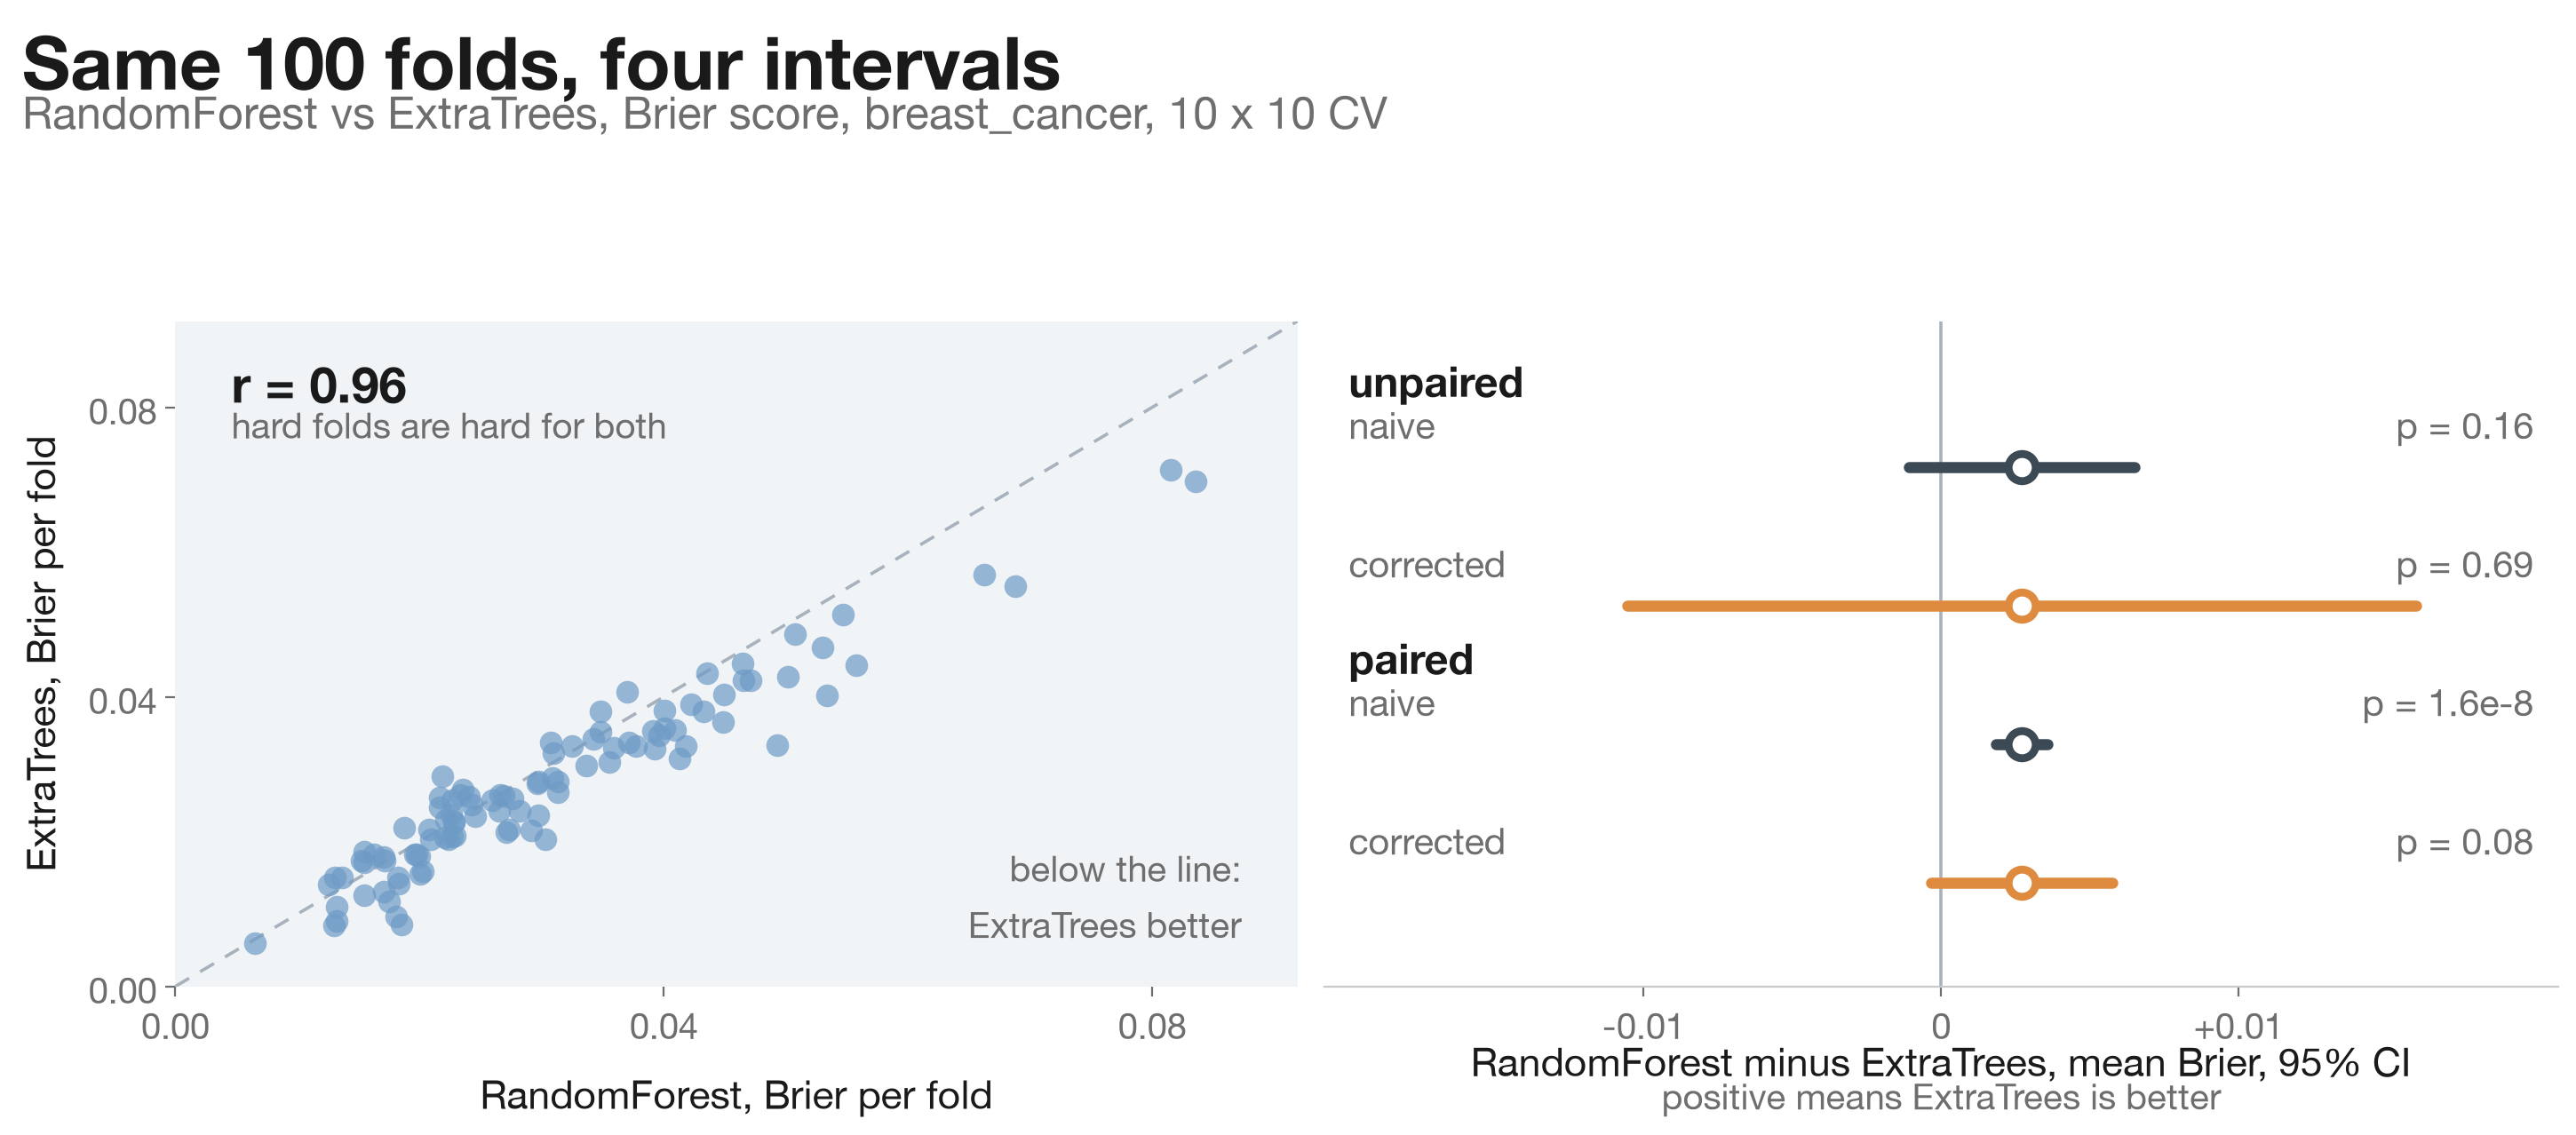

In [6]:
A, B = PAIRS[0]
AL, BL = "RandomForest", "ExtraTrees"
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]
SLATE, ORANGE, DOT = "#3C4A56", "#DE8A3F", "#6E9BC6"
INK, MUTED, RULE, PANEL = "#1a1a1a", "#6e6e6e", "#A7B2BC", "#F1F4F7"

a, b = S[A], S[B]
rows = CI[CI.pair == f"{A} - {B}"].reset_index(drop=True)   # unpaired then paired, naive then corrected

fig, axes = plt.subplots(1, 2, figsize=(14.6, 7.2), dpi=200, gridspec_kw={"width_ratios": [1, 1.1]})
fig.patch.set_facecolor("white")

# left: one point per fold, both models scored on it
ax = axes[0]
ax.set_facecolor(PANEL)
hi = max(a.max(), b.max())*1.1
ax.plot([0, hi], [0, hi], color=RULE, lw=1.3, ls=(0, (5, 4)), zorder=1)
ax.scatter(a, b, s=85, color=DOT, alpha=0.7, lw=0, zorder=3)
ax.text(0.05, 0.95, f"r = {a.corr(b):.2f}", transform=ax.transAxes, fontsize=20,
        fontweight="bold", color=INK, va="top")
ax.text(0.05, 0.875, "hard folds are hard for both", transform=ax.transAxes, fontsize=14.5,
        color=MUTED, va="top")
ax.text(0.95, 0.05, f"below the line:\n{BL} better", transform=ax.transAxes, fontsize=14.5,
        color=MUTED, ha="right", va="bottom", linespacing=1.35)
ax.set(xlim=(0, hi), ylim=(0, hi), xticks=[0, 0.04, 0.08], yticks=[0, 0.04, 0.08])
ax.set_xlabel(f"{AL}, Brier per fold", fontsize=16, color=INK, labelpad=10)
ax.set_ylabel(f"{BL}, Brier per fold", fontsize=16, color=INK, labelpad=10)
for sp in ax.spines.values():
    sp.set_visible(False)

# right: the same mean difference under the four standard errors
ax = axes[1]
ax.axvline(0, color=RULE, lw=1.3, zorder=1)
for i, r in rows.iterrows():
    yy = len(rows) - 1 - i
    color = SLATE if r.variance == "naive" else ORANGE
    ax.plot([r.est - r.half, r.est + r.half], [yy, yy], color=color, lw=4.5, solid_capstyle="round",
            zorder=3)
    ax.plot([r.est], [yy], marker="o", ms=11, mfc="white", mec=color, mew=3.2, zorder=4)
    if r.variance == "naive":
        ax.text(0.02, yy + 0.62, r.pairing, transform=ax.get_yaxis_transform(), fontsize=17,
                fontweight="bold", color=INK, va="center")
    ax.text(0.02, yy + 0.3, r.variance, transform=ax.get_yaxis_transform(), fontsize=15,
            color=MUTED, va="center")
    p = f"p = {r.p:.2g}" if r.p >= 0.01 else f"p = {r.p:.1e}".replace("e-0", "e-")
    ax.text(0.98, yy + 0.3, p, transform=ax.get_yaxis_transform(), fontsize=15, color=MUTED,
            ha="right", va="center")
span = (rows.est.abs() + rows.half).max()*1.3
ax.set_xlim(-span, span)
ax.set_ylim(-0.75, len(rows) - 1 + 1.05)
ax.set_yticks([])
ax.set_xticks([-0.01, 0, 0.01], ["-0.01", "0", "+0.01"])
ax.text(0.5, -0.135, f"{AL} minus {BL}, mean Brier, 95% CI", transform=ax.transAxes, fontsize=16,
        color=INK, ha="center")
ax.text(0.5, -0.185, f"positive means {BL} is better", transform=ax.transAxes, fontsize=14.5,
        color=MUTED, ha="center")
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
ax.spines["bottom"].set_color("#c9c9c9")

for ax in axes:
    ax.tick_params(labelsize=14.5, colors=MUTED, length=4)
fig.suptitle(f"Same {J} folds, four intervals", x=0.012, y=0.972, ha="left", fontsize=30,
             fontweight="bold", color=INK)
fig.text(0.012, 0.885, f"{AL} vs {BL}, Brier score, breast_cancer, {K} x {R} CV", fontsize=18,
         color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0.045, 1, 0.845])
fig.savefig("model_comparison_paired_cv.png", facecolor="white")
plt.show()

## Why more repeats do not help

A repeat of a `K`-fold split is one complete pass over the data: every row is tested on exactly once,
so the mean of a repeat's folds is one cross-validation estimate. Repeating the split `R` times gives
`R` of those estimates, and the spread between them is the only thing a repeat can measure, which is
how much the estimate depends on where the fold boundaries fell.

That spread comes out well below what independent folds would give, and averaging more repeats
shrinks the interval built from it without bound. This is the trap: the naive standard error reads
stability under re-splitting as precision, when the rows are the same rows in every repeat.

In [7]:
print("what re-splitting the same rows measures")
for a_name, b_name in PAIRS:
    d = (S[a_name] - S[b_name]).values.reshape(R, K)   # RepeatedStratifiedKFold runs repeat by repeat
    rep = d.mean(axis=1)                               # one complete K-fold estimate per repeat
    within = np.sqrt(d.var(axis=1, ddof=1).mean())     # spread of folds inside a repeat, pooled
    print(f"  {a_name} - {b_name}: naive SE {d.std(ddof=1)/np.sqrt(J):.5f}, "
          f"sd between the {R} repeat means {rep.std(ddof=1):.5f}, "
          f"against {within/np.sqrt(K):.5f} if the folds within a repeat were independent")

what re-splitting the same rows measures
  RF - ET: naive SE 0.00044, sd between the 10 repeat means 0.00088, against 0.00143 if the folds within a repeat were independent
  LR - RF: naive SE 0.00106, sd between the 10 repeat means 0.00140, against 0.00349 if the folds within a repeat were independent


## Pairing is the fold, not the seed

A tempting shortcut is to give both models the same `random_state` and call them paired. The scores
above were deliberately built the other way, a different seed for every model and fold, so this cell
checks what the shortcut is worth: one fixed split, both models refitted under many seeds, and the
correlation between their scores when the seed is shared against when it is not.

In [8]:
NSEED = 100
t0 = time.time()
for split_seed in (0, 1):
    tr, te = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=split_seed)
    rf = [brier_of(MODELS["RF"](s), X, y, tr, te) for s in range(NSEED)]
    shared = [brier_of(MODELS["ET"](s), X, y, tr, te) for s in range(NSEED)]
    indep = [brier_of(MODELS["ET"](s + 10_000), X, y, tr, te) for s in range(NSEED)]
    print(f"  split {split_seed}: correlation {np.corrcoef(rf, shared)[0, 1]:+.2f} on a shared seed, "
          f"{np.corrcoef(rf, indep)[0, 1]:+.2f} on independent seeds")
print(f"{time.time() - t0:.0f}s, {NSEED} seeds per model and split, {NTREE} trees; a correlation on "
      f"{NSEED} points carries a standard error of about {1/np.sqrt(NSEED):.2f}")

  split 0: correlation -0.01 on a shared seed, -0.12 on independent seeds


  split 1: correlation -0.11 on a shared seed, +0.05 on independent seeds
115s, 100 seeds per model and split, 300 trees; a correlation on 100 points carries a standard error of about 0.10


## Which of the four intervals is right

Nothing above settles that, because every number came from one dataset. So here the population is
known: one draw from a generator, cut into `NDATA` samples of equal size, with the whole paired
comparison rerun on each. The spread of the resulting differences is the thing a standard error is
supposed to predict, and it is also the question an interval is asked in practice, which is how much
of the difference would survive another sample of the same size.

Smaller than the run above, to keep it to a few minutes: fewer rows, fewer trees, `KV` x `RV` folds.
The generator's seed fixes the class centroids as well as the sample, so drawing a fresh one per
sample would vary the problem rather than the sample of it, which is why there is only one draw.

In [9]:
NDATA, NROWS, KV, RV, NTREE_V = 40, 600, 5, 5, 100
JV = KV*RV

# one draw, then slices: make_classification's random_state fixes the class centroids as well as the
# sample, so a new random_state per dataset would vary the problem and not just the sample of it
XA, yA = make_classification(n_samples=NDATA*NROWS, n_features=20, n_informative=6, n_redundant=4,
                             class_sep=0.8, flip_y=0.03, random_state=0)
t0 = time.time()
est, se_naive = [], []
for d in range(NDATA):
    Xv, yv = XA[d*NROWS:(d + 1)*NROWS], yA[d*NROWS:(d + 1)*NROWS]
    fv = list(RepeatedStratifiedKFold(n_splits=KV, n_repeats=RV, random_state=1000 + d).split(Xv, yv))
    sv = pd.DataFrame({m: [brier_of(MODELS[m](2*(d*JV + i) + j, NTREE_V), Xv, yv, tr, te)
                           for i, (tr, te) in enumerate(fv)]
                       for j, m in enumerate(("RF", "ET"))})
    dv = sv.RF - sv.ET
    est.append(dv.mean())
    se_naive.append(dv.std(ddof=1)/np.sqrt(JV))

est, se_naive = np.array(est), np.array(se_naive)
inflate_v = inflation(JV, len(fv[0][1]), len(fv[0][0]))
tcrit_v = stats.t.ppf(0.975, JV - 1)
print(f"{time.time() - t0:.0f}s, {NDATA} samples of {NROWS} rows from one population, "
      f"{KV} x {RV} CV, inflation {inflate_v:.2f}x")
print(f"the difference itself: mean over the {NDATA} samples {est.mean():+.5f}, "
      f"sd between them {est.std(ddof=1):.5f}")
for label, se in (("naive", se_naive), ("corrected", se_naive*inflate_v)):
    covers = np.mean(np.abs(est - est.mean()) <= tcrit_v*se)
    print(f"  {label:10s} mean SE {se.mean():.5f}: the sd between samples is "
          f"{est.std(ddof=1)/se.mean():.2f}x that, and its 95% interval holds that mean "
          f"{covers:.0%} of the time")

155s, 40 samples of 600 rows from one population, 5 x 5 CV, inflation 2.69x
the difference itself: mean over the 40 samples +0.00089, sd between them 0.00208
  naive      mean SE 0.00115: the sd between samples is 1.81x that, and its 95% interval holds that mean 80% of the time
  corrected  mean SE 0.00308: the sd between samples is 0.67x that, and its 95% interval holds that mean 100% of the time


## What this notebook measured

Pairing is worth what the two models have in common. On two forests that differ only in how their
splits are chosen, the fold scores move together almost exactly, and pairing cuts the standard error
several times over. On a linear model against a forest, the shared part is smaller and so is the gain.
That part of the usual advice holds: compare the differences, not the columns.

What does not hold is the divisor. Every fold of a repeated cross-validation trains on nearly the same
rows, so the `J` fold scores are nowhere near `J` independent measurements, and dividing their spread
by the square root of `J` produces an interval that is too narrow by a factor set by the design alone.
With a tenth of the rows held out, that factor is large enough to turn the forests' difference from
overwhelming to inconclusive, while the linear model's difference survives it.

The repeats are not the fix. Each repeat is a complete pass over the same rows, so the only thing the
spread between repeats can see is where the fold boundaries fell, and adding repeats narrows the
interval built from it without touching the uncertainty that matters.

Sharing a `random_state` between two models is not pairing either. Under one fixed split, neither the
shared-seed nor the independent-seed correlation separates from zero by more than the standard error
that many seeds carry, so the shortcut buys nothing measurable: a seed means something different
inside each algorithm, and setting it to the same integer holds nothing in common. The correlation
that pairing exploits comes from the fold.

The last cell is the check that makes the rest of it falsifiable. One population, `NDATA` samples of
the same size cut from it, the whole comparison rerun on each: the difference moves from sample to
sample by nearly twice what the naive standard error claims, and the naive interval holds the average
of those samples far less often than the 95% it advertises. The corrected standard error misses in the
other direction. It comes out larger than the spread it is predicting, and its interval holds that
average every time, so on this design the correction is not a calibrated variance. It is a guard
against calling a winner too early.

That asymmetry is worth carrying back to the forests above. Their naive interval is demonstrably too
narrow, and their corrected one is wide enough and then some, so inconclusive is the cautious reading
of that row rather than a measured absence of a difference.

What the check does not settle is the size of either error: one generator, one sample size, one pair
of models and one ratio of test rows to training rows. What it does settle is the direction of both.